## Assignment no 12

## Random Forest Classification Using the Glass Dataset

1. Understanding the Glass Dataset

2. Import Required Libraries

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

3. Load the Dataset

In [28]:
# Load dataset
excel_path = 'glass.xlsx'

df = pd.read_excel(excel_path, sheet_name='glass')

# Display first five records
print("First 5 Records:")
display(df.head())

# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

First 5 Records:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Dataset Shape: (214, 10)

Column Names:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type']


4. Exploratory Data Analysis (EDA)

4.1 Dataset Information

In [29]:
# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


Number of Rows: 214
Number of Columns: 10


4.2 Check Missing Values


In [30]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Total Missing Values: 0


4.3 Check Duplicate Records

In [31]:
# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Remove duplicate records if present
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Records: 1
Dataset Shape After Removing Duplicates: (213, 10)


4.4 Target Variable Distribution

In [32]:
# Count glass types
print(df['Type'].value_counts().sort_index())

# Percentage distribution
print("\nClass Distribution (%):")
print(df['Type'].value_counts(normalize=True).sort_index() * 100)

Type
1    69
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64

Class Distribution (%):
Type
1    32.394366
2    35.680751
3     7.981221
5     6.103286
6     4.225352
7    13.615023
Name: proportion, dtype: float64


4.5 Check Outliers Using IQR

The Interquartile Range (IQR) method identifies potential outliers.

Formula:
\[
IQR = Q3-Q1
\]

\[
Lower=Q1-1.5(IQR)
\]

\[
Upper=Q3+1.5(IQR)
\]

In [33]:
# Select numerical input features
X_eda = df.drop(columns=['Type'])

# Remove an optional ID column if present
X_eda = X_eda.drop(columns=['Id'], errors='ignore')

# Calculate outliers
Q1 = X_eda.quantile(0.25)
Q3 = X_eda.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((X_eda < lower_bound) | (X_eda > upper_bound)).sum()

print("Outliers in Each Feature:")
print(outliers)

Outliers in Each Feature:
RI    17
Na     7
Mg     0
Al    17
Si    12
K      7
Ca    27
Ba    38
Fe    12
dtype: int64


5. Data Visualization

5.1 Histograms

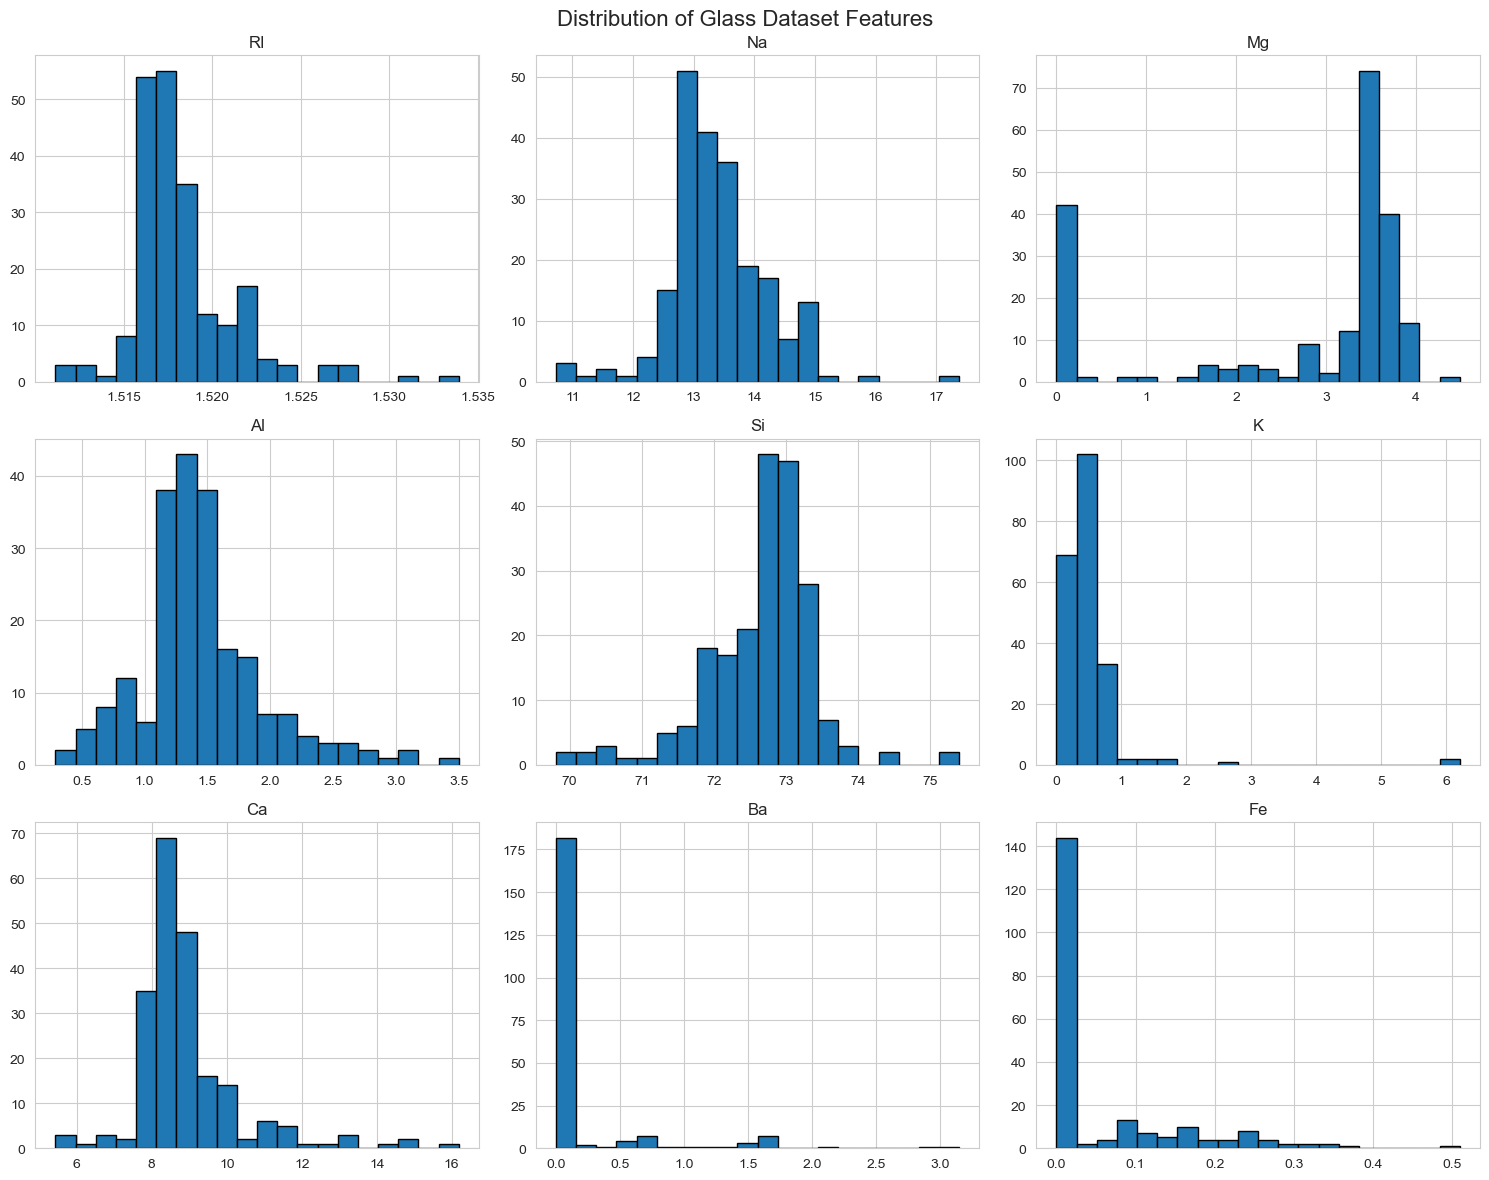

In [34]:
X_eda.hist(figsize=(15, 12), bins=20, edgecolor='black')

plt.suptitle('Distribution of Glass Dataset Features', fontsize=16)
plt.tight_layout()
plt.show()

5.2 Box Plots

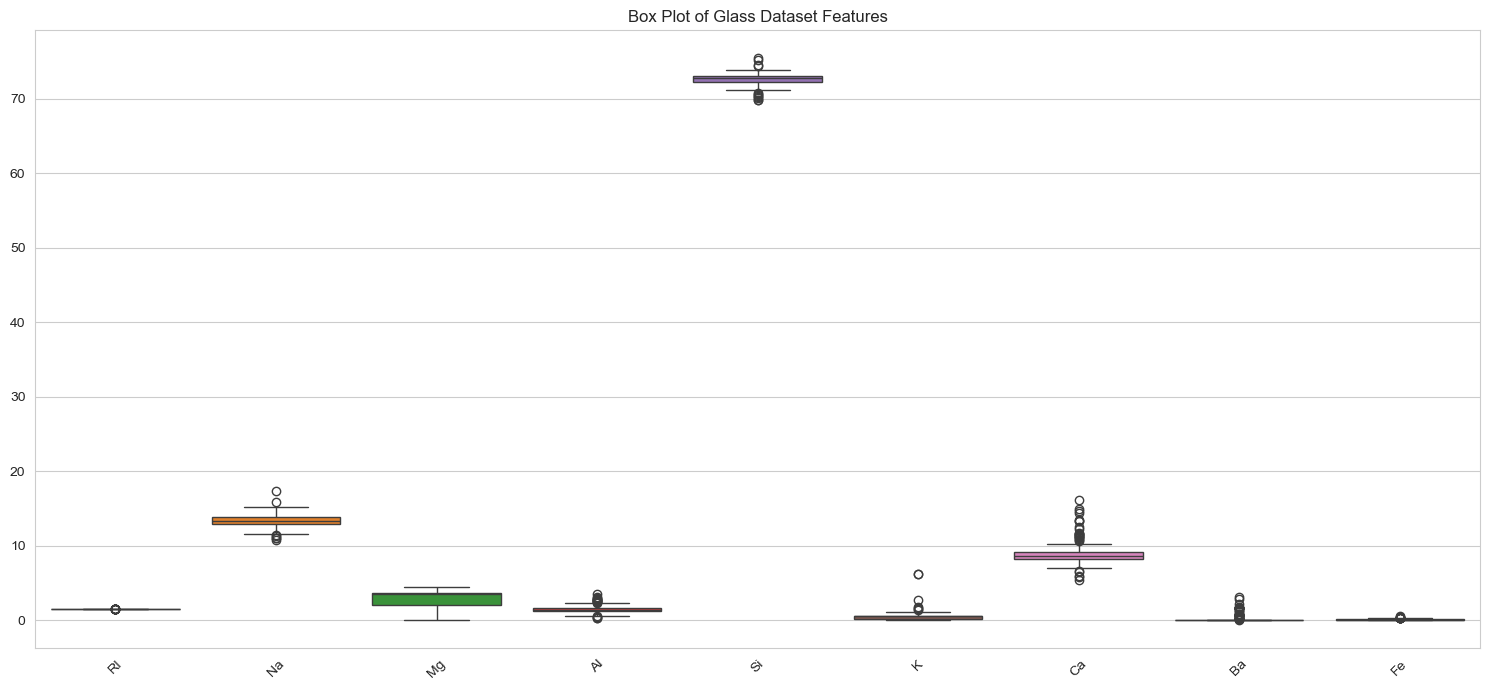

In [35]:
plt.figure(figsize=(15, 7))

sns.boxplot(data=X_eda)

plt.title('Box Plot of Glass Dataset Features')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

5.3 Correlation Heatmap

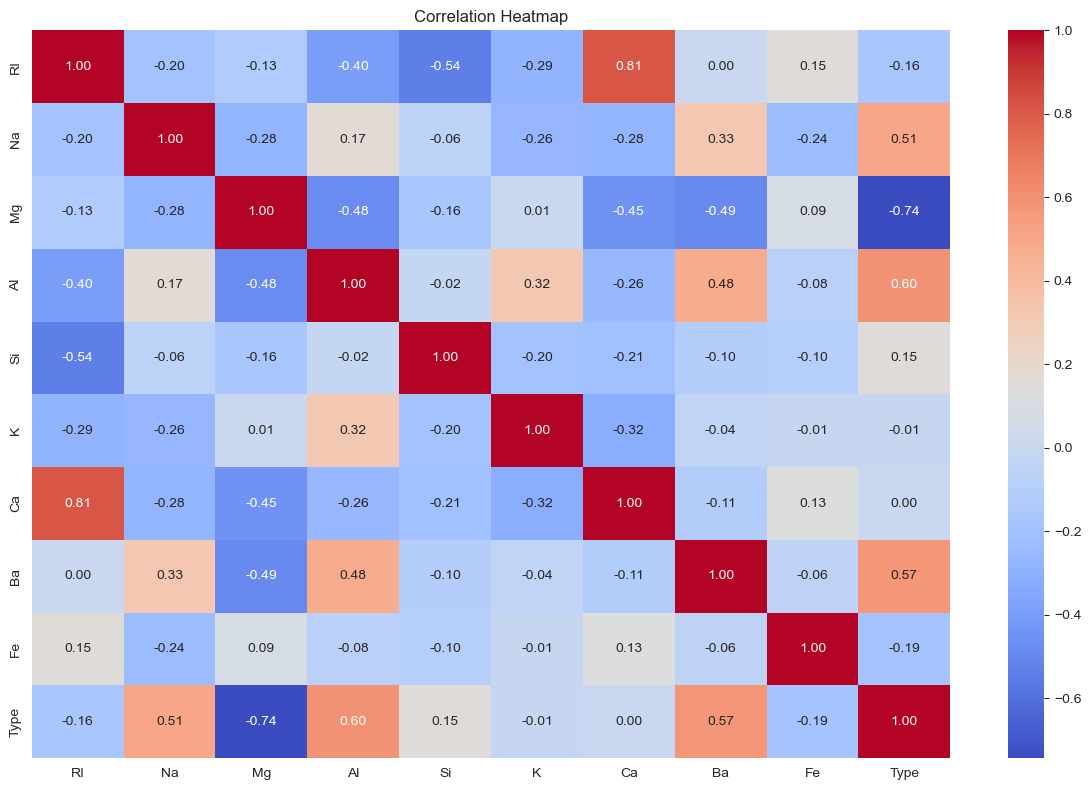

In [36]:
plt.figure(figsize=(12, 8))

correlation = df.drop(columns=['Id'], errors='ignore').corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

5.4 Pair Plot

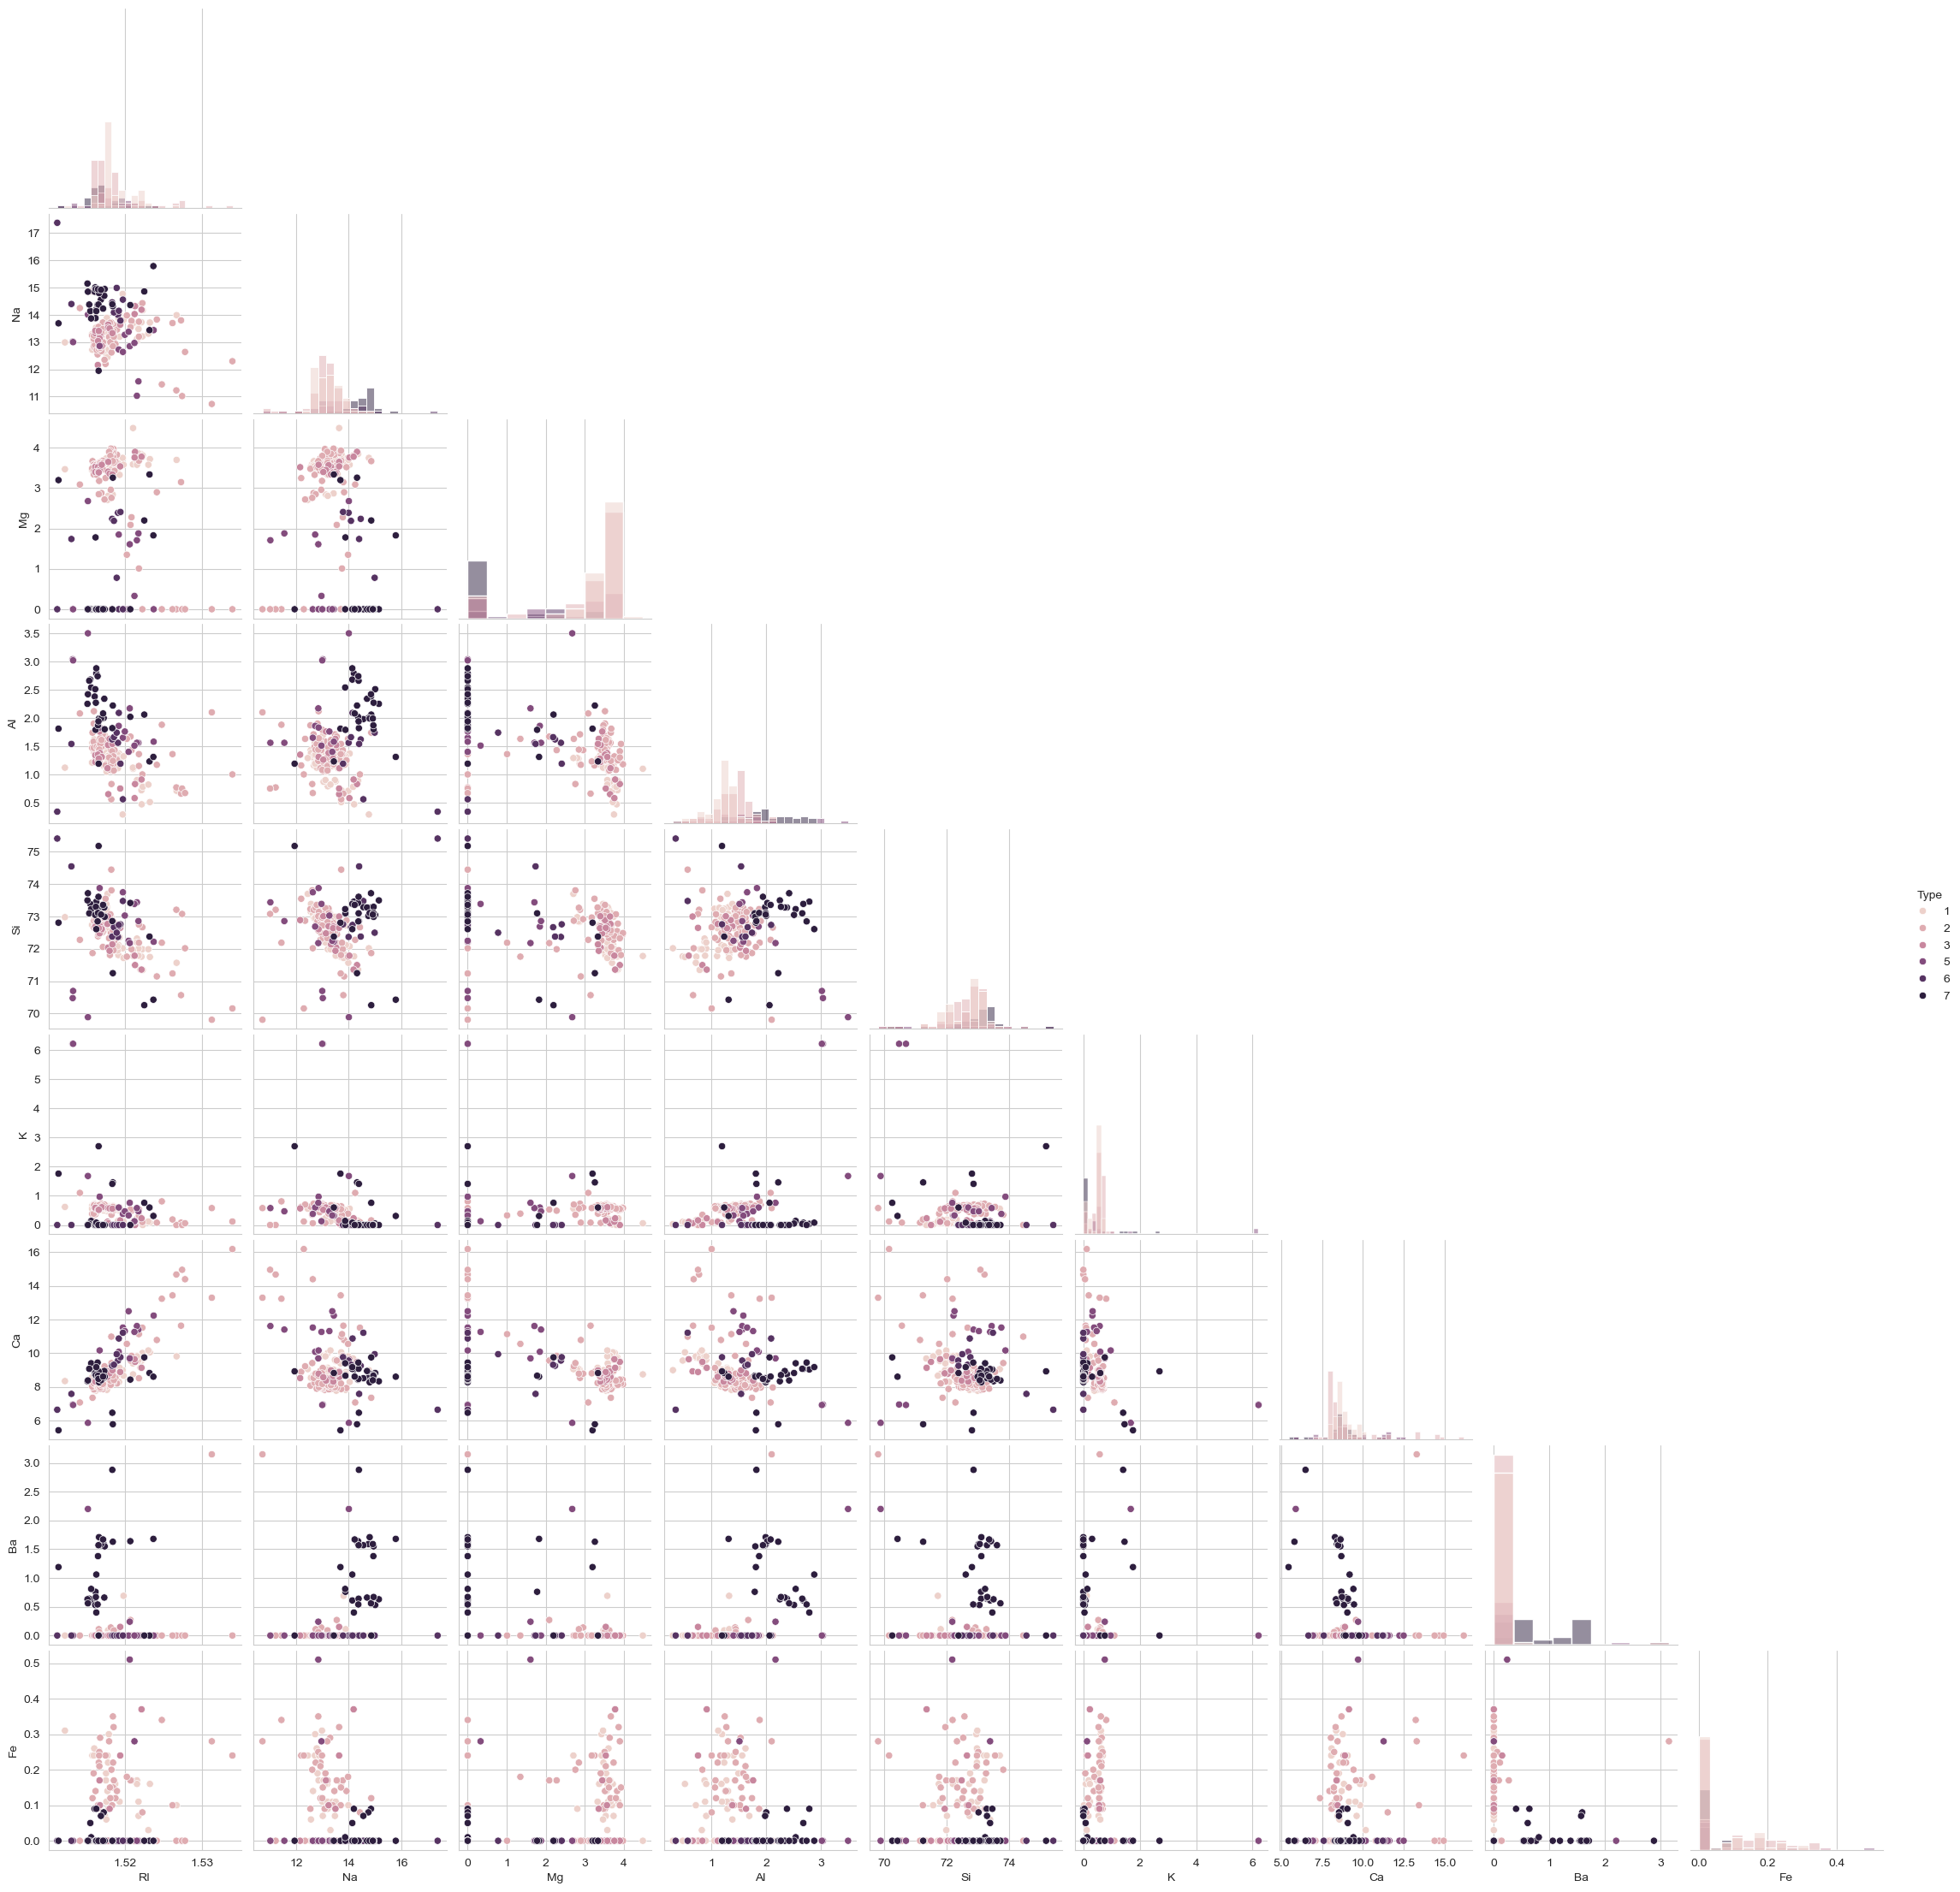

In [37]:
sns.pairplot(
    df.drop(columns=['Id'], errors='ignore'),
    hue='Type',
    diag_kind='hist',
    corner=True
)

plt.show()

5.5 Target Class Distribution

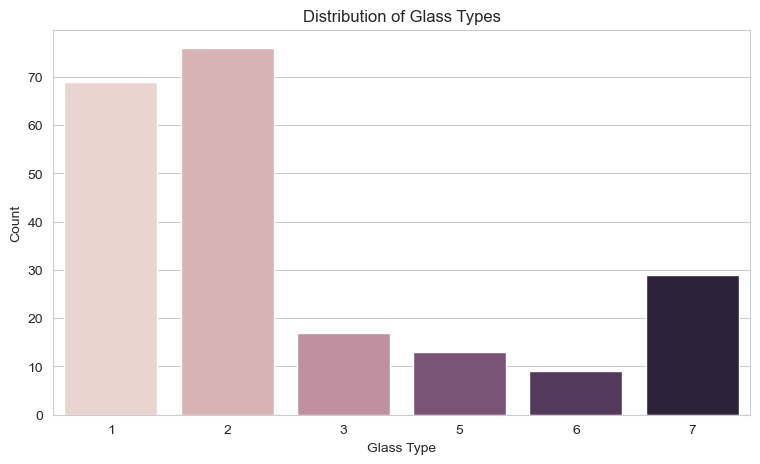

In [38]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Type', hue='Type', legend=False)

plt.title('Distribution of Glass Types')
plt.xlabel('Glass Type')
plt.ylabel('Count')

plt.show()

6. Data Preprocessing

6.1 Separate Features and Target

In [39]:
# Remove target column from input features
X = df.drop(columns=['Type', 'Id'], errors='ignore')

# Target variable
y = df['Type']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature Shape: (213, 9)
Target Shape: (213,)

Features:
['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

Training Data: (170, 9)
Testing Data: (43, 9)

Training Class Distribution:
Type
1    55
2    61
3    14
5    10
6     7
7    23
Name: count, dtype: int64

Testing Class Distribution:
Type
1    14
2    15
3     3
5     3
6     2
7     6
Name: count, dtype: int64


Implement Random Forest

In [41]:
# Create preprocessing pipeline
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocess training and testing data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    max_features='sqrt'
)

# Train model
rf_model.fit(X_train_processed, y_train)

# Predictions
rf_pred = rf_model.predict(X_test_processed)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


Evaluate Random Forest

In [42]:
print("Random Forest Performance")

print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Precision:",
      precision_score(y_test, rf_pred, average='macro', zero_division=0))

print("Recall:",
      recall_score(y_test, rf_pred, average='macro', zero_division=0))

print("F1 Score:",
      f1_score(y_test, rf_pred, average='macro', zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

Random Forest Performance
Accuracy: 0.8372093023255814
Precision: 0.8777777777777778
Recall: 0.8595238095238095
F1 Score: 0.8561128526645768

Classification Report:
              precision    recall  f1-score   support

           1       0.80      0.86      0.83        14
           2       0.80      0.80      0.80        15
           3       1.00      0.67      0.80         3
           5       1.00      1.00      1.00         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.84        43
   macro avg       0.88      0.86      0.86        43
weighted avg       0.85      0.84      0.84        43



Confusion Matrix

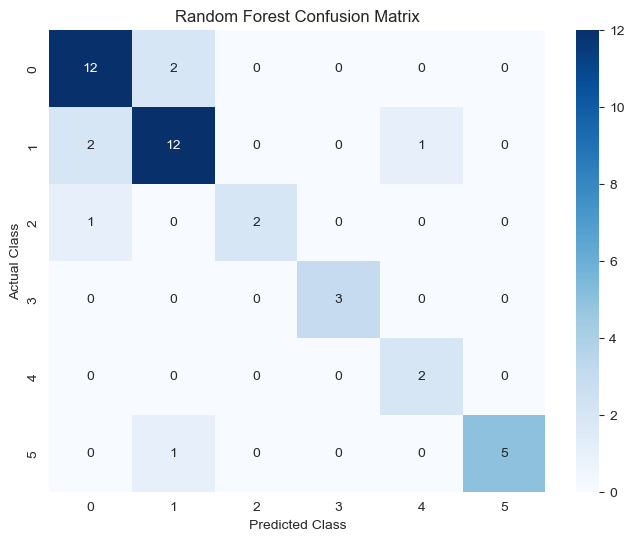

In [43]:
cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

Feature Importance

  Feature  Importance
2      Mg    0.182210
6      Ca    0.139319
1      Na    0.133324
5       K    0.130525
3      Al    0.117971
0      RI    0.107215
4      Si    0.085644
7      Ba    0.080428
8      Fe    0.023365


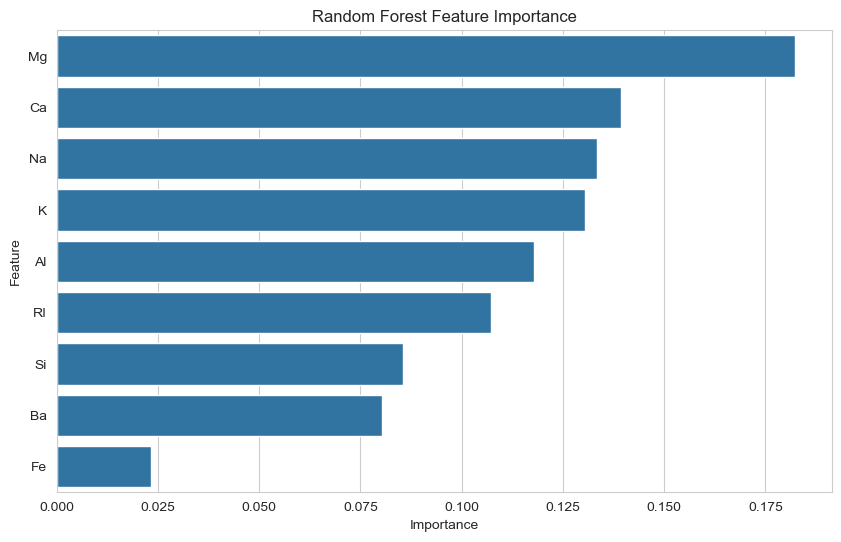

In [44]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.show()

Hyperparameter Tuning Using GridSearchCV

In [45]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    param_grid=param_grid,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)

best_rf = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross Validation Score:
0.748526459473486


In [46]:
best_rf_pred = best_rf.predict(X_test_processed)

print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, best_rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_rf_pred,
    zero_division=0
))

Tuned Random Forest Accuracy: 0.7674418604651163

Classification Report:
              precision    recall  f1-score   support

           1       0.79      0.79      0.79        14
           2       0.77      0.67      0.71        15
           3       0.50      0.67      0.57         3
           5       0.75      1.00      0.86         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.77        43
   macro avg       0.75      0.83      0.77        43
weighted avg       0.78      0.77      0.77        43



Bagging Method


Implement Bagging Classifier

In [47]:
# Base estimator
base_tree = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

# Create Bagging Classifier
bagging_model = BaggingClassifier(
    estimator=base_tree,
    n_estimators=100,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Train model
bagging_model.fit(X_train_processed, y_train)

# Predictions
bagging_pred = bagging_model.predict(X_test_processed)

print("Bagging Model Training Completed!")

Bagging Model Training Completed!


Evaluate Bagging

In [48]:
print("Bagging Model Performance")

print("Accuracy:",
      accuracy_score(y_test, bagging_pred))

print("Precision:",
      precision_score(y_test, bagging_pred, average='macro', zero_division=0))

print("Recall:",
      recall_score(y_test, bagging_pred, average='macro', zero_division=0))

print("F1 Score:",
      f1_score(y_test, bagging_pred, average='macro', zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    bagging_pred,
    zero_division=0
))


Bagging Model Performance
Accuracy: 0.7906976744186046
Precision: 0.811111111111111
Recall: 0.7928571428571428
F1 Score: 0.7894461859979102

Classification Report:
              precision    recall  f1-score   support

           1       0.80      0.86      0.83        14
           2       0.73      0.73      0.73        15
           3       1.00      0.67      0.80         3
           5       0.67      0.67      0.67         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.79        43
   macro avg       0.81      0.79      0.79        43
weighted avg       0.80      0.79      0.79        43



Bagging Confusion Matrix

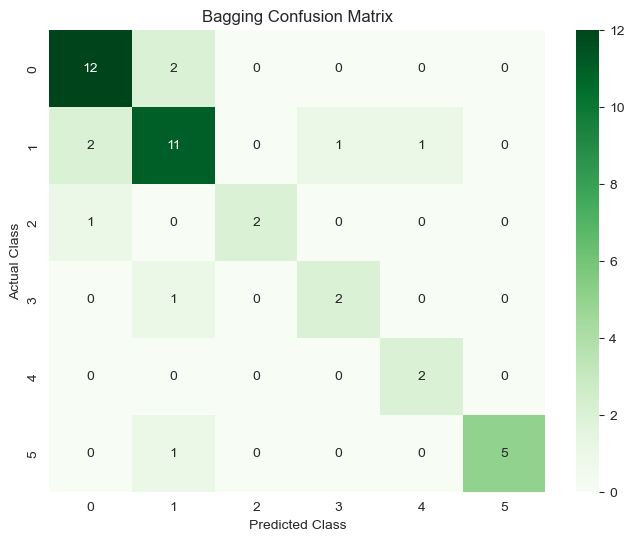

In [49]:
cm = confusion_matrix(y_test, bagging_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Bagging Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

Boosting Method

Implement AdaBoost Classifier

In [50]:
# Create weak learner
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    class_weight='balanced',
    random_state=42
)

# Create AdaBoost model
boosting_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train model
boosting_model.fit(X_train_processed, y_train)

# Predictions
boosting_pred = boosting_model.predict(X_test_processed)

print("Boosting Model Training Completed!")

Boosting Model Training Completed!


Evaluate Boosting

In [51]:
print("Boosting Model Performance")

print("Accuracy:",
      accuracy_score(y_test, boosting_pred))

print("Precision:",
      precision_score(y_test, boosting_pred, average='macro', zero_division=0))

print("Recall:",
      recall_score(y_test, boosting_pred, average='macro', zero_division=0))

print("F1 Score:",
      f1_score(y_test, boosting_pred, average='macro', zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    boosting_pred,
    zero_division=0
))

Boosting Model Performance
Accuracy: 0.6511627906976745
Precision: 0.6758563074352547
Recall: 0.5904761904761905
F1 Score: 0.603874883286648

Classification Report:
              precision    recall  f1-score   support

           1       0.64      0.64      0.64        14
           2       0.58      0.73      0.65        15
           3       0.00      0.00      0.00         3
           5       1.00      0.33      0.50         3
           6       1.00      1.00      1.00         2
           7       0.83      0.83      0.83         6

    accuracy                           0.65        43
   macro avg       0.68      0.59      0.60        43
weighted avg       0.64      0.65      0.63        43



Boosting Confusion Matrix

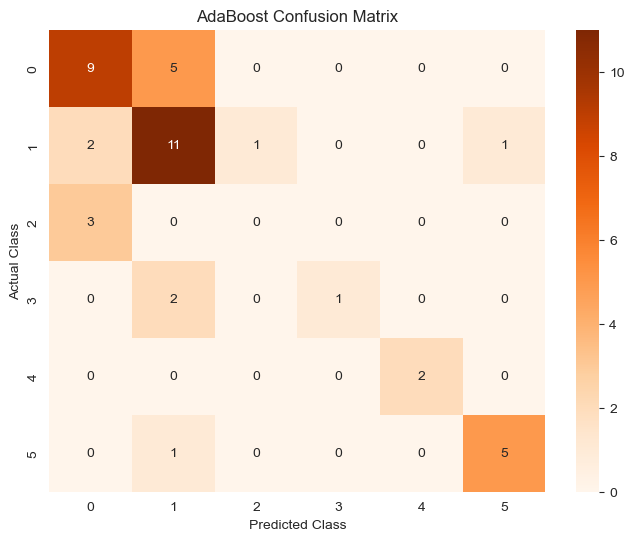

In [52]:
cm = confusion_matrix(y_test, boosting_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.title('AdaBoost Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()

Comparison Between Random Forest, Bagging and Boosting

Model Comparison

In [53]:
# Predictions from all models
rf_final_pred = best_rf.predict(X_test_processed)

# Calculate performance metrics
results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'Bagging',
        'AdaBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, rf_final_pred),
        accuracy_score(y_test, bagging_pred),
        accuracy_score(y_test, boosting_pred)
    ],

    'Precision': [
        precision_score(y_test, rf_final_pred, average='macro', zero_division=0),
        precision_score(y_test, bagging_pred, average='macro', zero_division=0),
        precision_score(y_test, boosting_pred, average='macro', zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, rf_final_pred, average='macro', zero_division=0),
        recall_score(y_test, bagging_pred, average='macro', zero_division=0),
        recall_score(y_test, boosting_pred, average='macro', zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, rf_final_pred, average='macro', zero_division=0),
        f1_score(y_test, bagging_pred, average='macro', zero_division=0),
        f1_score(y_test, boosting_pred, average='macro', zero_division=0)
    ]
})

print("Model Performance Comparison:")
display(results.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.7674,0.7453,0.8254,0.7729
1,Bagging,0.7907,0.8111,0.7929,0.7894
2,AdaBoost,0.6512,0.6759,0.5905,0.6039


Visualization of Model Comparison

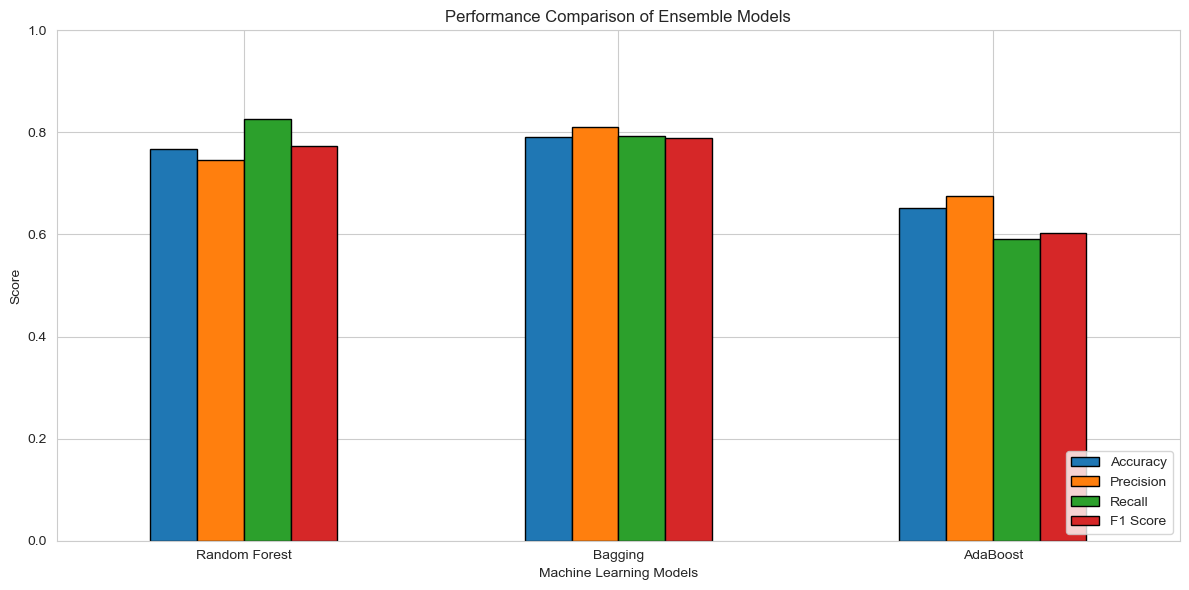

In [54]:
results_plot = results.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(12, 6),
    ylim=(0, 1),
    edgecolor='black'
)

plt.title('Performance Comparison of Ensemble Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()

plt.show()

Identify the Best Model

In [55]:
best_model = results.loc[
    results['F1 Score'].idxmax()
]

print("Best Performing Model:")
print(best_model)

print("\nBest Model Name:", best_model['Model'])
print("Best Accuracy:", round(best_model['Accuracy'], 4))
print("Best F1 Score:", round(best_model['F1 Score'], 4))

Best Performing Model:
Model         Bagging
Accuracy     0.790698
Precision    0.811111
Recall       0.792857
F1 Score     0.789446
Name: 1, dtype: object

Best Model Name: Bagging
Best Accuracy: 0.7907
Best F1 Score: 0.7894
